In [1]:
# -----------------------------------------------
# ESTE EJERCICIO SE ENFOCA A PROBAR LA FUNCION LOGISTICA
# CLASIFICAR VALORES ENTRE 0 y 1
# ------------------------------------------------



#importamos la libreria y cargamos el archivo
import pandas as pd
datos = pd.read_csv("U4_04_train.csv")

# 1. VISUALIZAMOS INFO. BASICA DEL DATASET

In [2]:
#vista previa de los datos
datos.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
#Vemos los tipos de datos , columnas que tiene el DataSet
# ya que Machine Learning trabaja con datos numericos
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
# Exploramos datos interesantes Del DataSet
#La función describe() en Python, cuando se aplica a un conjunto de datos (por ejemplo, un DataFrame de pandas), proporciona un resumen estadístico de las columnas numéricas. Los valores que devuelve son los siguientes:
# count: El número de elementos no nulos en la columna. Este valor indica cuántas observaciones hay en la muestra.
# mean: La media aritmética de los valores en la columna. Se calcula sumando todos los valores y dividiendo por el número de elementos.
# std: La desviación estándar de los valores en la columna. La desviación estándar es una medida de dispersión que indica cuánto varían los valores de la media.
# min: El valor mínimo en la columna, es decir, el valor más pequeño.
# 25%: El percentil 25, también conocido como el primer cuartil o Q1. Indica el valor por debajo del cual se encuentra el 25% de los datos.
# 50%: El percentil 50, que es la mediana. Indica el valor que separa la mitad superior de la mitad inferior de los datos cuando están ordenados de menor a mayor.
# 75%: El percentil 75, también conocido como el tercer cuartil o Q3. Indica el valor por debajo del cual se encuentra el 75% de los datos.
# max: El valor máximo en la columna, es decir, el valor más grande.
datos.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
# Visualizamos los datos que estan vacios
datos.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

# 2. GRAFICAMOS ALGUNOS DATOS INMPORTANTES 

<Axes: xlabel='Survived', ylabel='count'>

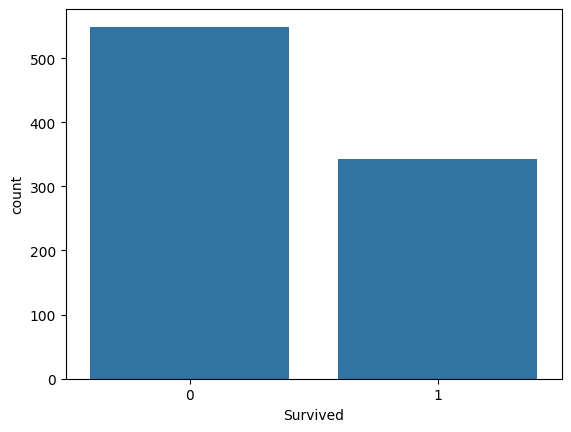

In [6]:
# 2.1 Graficamos los que sobrevivieron y los que NO. 0 = NO y 1 = SO
import seaborn as sb
sb.countplot(x="Survived", data=datos)

<Axes: xlabel='Survived', ylabel='count'>

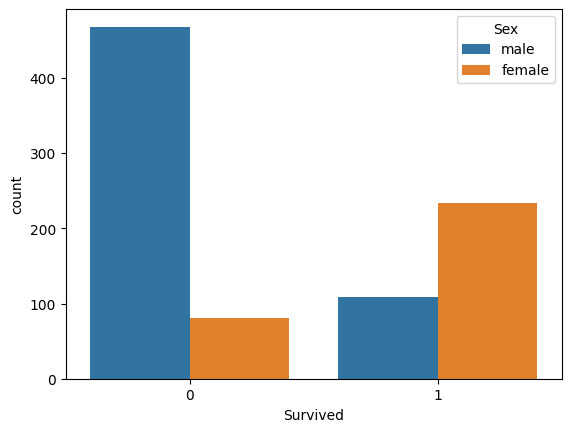

In [7]:
# 2.2 Graficamos los que sobrevivieron segun el sexo
sb.countplot(x="Survived", data=datos, hue="Sex")

# Lo que nos dice es :
# Los que no sobrevivieron la mayoria eran hombres
# Los que SI Sobrevivieron la mayoria eran mujeres

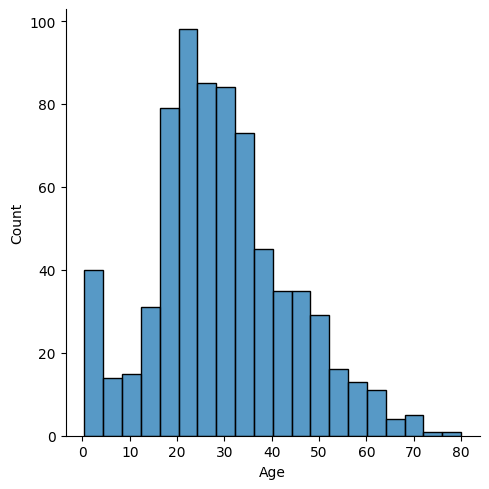

In [8]:
# 2.3 Viaulizamos la distribucion de las edades. 
sb.displot(x="Age",data = datos)

# NOTA: la grafica nos muestra que las edades estan cargados a la izquierda

# 2. TRANSFORMAOS EL DATA SET (LIMPIAMOS Y AJUSTAMOS)

In [9]:
# 3.1 # Visualizamos los datos que estan vacios
datos.isna().sum()

# NOTA : los datos de edad 177 registros estan vacios del total de 891 Registros
# por lo cual no los podemos eliminar ya que son muchos. por lo tanto los llenaremos
# con un promedio de edad

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
# 3.2 Agregamos los datos vacios con el promedio de edad
datos["Age"]  = datos["Age"].fillna(datos["Age"].mean())

In [11]:
# 3.4 Validamos que estaen llenos
datos.isna().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [12]:
# 3.5 Eliminamos los datos de cabina ya que tal campo no nos es util
datos = datos.drop(["Cabin"], axis=1)

In [13]:
# 3.4 Validamos que no este el campo cabina ya que fue eliminado
datos.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64

In [14]:
# 3.5 Eliminamos los datos NA
datos = datos.dropna()

In [15]:
# 3.5.1 Validamos que no este el campo Embarked ya que fue eliminado
datos.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [16]:
# 3.6. QUitamos el Name, PassengerID y Ticket 
datos = datos.drop(["Name","PassengerId","Ticket"], axis =1) 

In [17]:
# 3.6.1 Viaulizamos los datos para validar las columnas
datos.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [18]:
# 3.7 Convertimos la columna Sex a una columna numerica
dummies_sex = pd.get_dummies(datos["Sex"], 
               drop_first = True, # La opcion drop_first elimina la redundancia ,
               dtype = int
)
# NOTA: Esta redundancia tambien evita "Milticolinearity" 


In [19]:
# 3.7.1 Agregamos el dummies_sex al datos
datos = datos.join(dummies_sex)
datos = datos.drop(["Sex"], axis=1)


<Axes: xlabel='Survived', ylabel='count'>

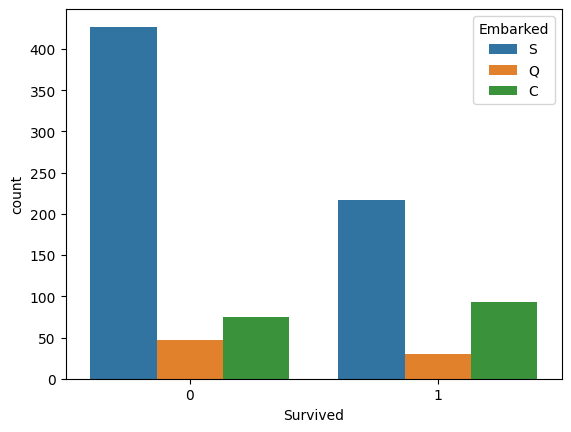

In [20]:
# 3.8 Validamos la columna Embarked para saber si se puede transoformar o bien eliminar
sb.countplot(x="Survived", data = datos, hue="Embarked")
# Esta grafica nos dice quienes fueron sobrevivientes apartir del embarque
# pero no queda tan claro en la grafica, por ello creamos dummies de Embarked

In [21]:
# 3.8.1 Convertimos la columna Embarked a una columna numerica
dummies_embarked = pd.get_dummies(datos["Embarked"], 
               drop_first = True, # La opcion drop_first elimina la redundancia ,
               dtype = int
)
# NOTA: Esta redundancia tambien evita "Milticolinearity" 

In [22]:
# 3.8.1 Agregamos el embarked_sex al datos
datos = datos.join(dummies_embarked)
datos = datos.drop(["Embarked"], axis=1)

In [23]:
# 3.8.2 Vemos las columnas
datos.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,male,Q,S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


<Axes: >

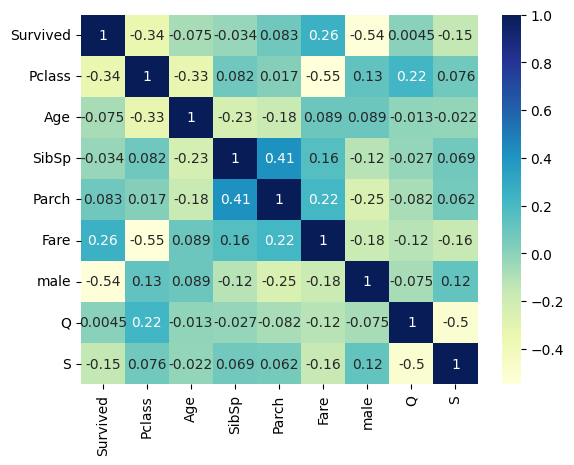

In [24]:

# 3.9 Vemos la correlacion de las caracteristicas
sb.heatmap(datos.corr(), annot=True, cmap="YlGnBu")

In [25]:
# 3.9.1 Vemos la correlacion de la cariables que nos interesa "Survived" 
#con las demnas
datos.corr()["Survived"].sort_values(ascending=False)

# NOTA: Lo que nos dice es que tiene mas relacion con las caracteristicas de
# Fare, es decir los que mas pagaron seguidos de Parch y del embarque Q
# Tambien podemos ver que PClass tiene una relacion negativa es decir 
# los de menor clase son los que menos sobrevivieron, podemos verlo en la siguiente
# Grafica


Survived    1.000000
Fare        0.255290
Parch       0.083151
Q           0.004536
SibSp      -0.034040
Age        -0.074673
S          -0.151777
Pclass     -0.335549
male       -0.541585
Name: Survived, dtype: float64

<Axes: xlabel='Survived', ylabel='count'>

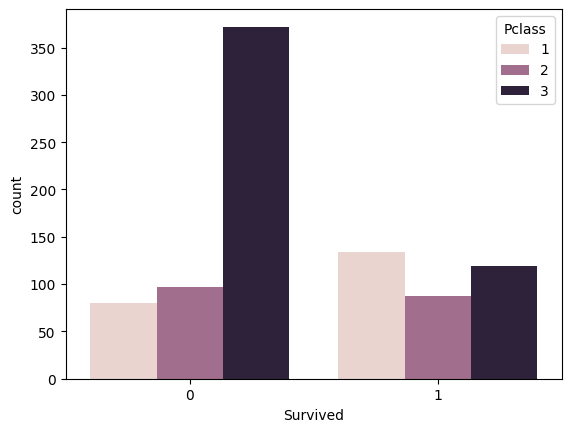

In [26]:
# 3.9.2 Ver la relacion de los que NO sobrevivieron lo la Clase
sb.countplot(x="Survived",data=datos, hue="Pclass")
# La grafica nos indica que los que no sobrevivieron fueron de la 3era clase

# 3. COMENZAMOS CON EL ENTRENAMIENTO DE NUESTRO MODELO - LOGISTIC REGRESION

In [27]:
# 4. Separamos nuestras entradas y Salidas
X = datos.drop(["Survived"], axis=1) # Eliminamos la columna Survived ya que todas 
# las demas seran nuestras entradas
Y = datos["Survived"] # Nuestra salida deseada sera Survived

In [28]:
# 4.1 Importamos el modelo para separa las variables de Entrenamiento y Pruebas.
from sklearn.model_selection import train_test_split
X_ent, X_pruebas , Y_Ent, Y_Pruebas = train_test_split(X,Y, test_size=.2)

In [29]:
# 4.2 Importamos los arboles de desicion
from sklearn.tree import DecisionTreeClassifier
modelo = DecisionTreeClassifier(max_depth=50)
modelo.fit(X_ent,Y_Ent)
predicciones = modelo.predict(X_pruebas)

In [30]:
# 5.1 Validamos la exactitud del modelo
from sklearn.metrics import accuracy_score
accuracy_score(Y_Pruebas, predicciones)

0.797752808988764

In [34]:
# 4.2 Probamos los arboles de desicion para iterarlos y saber cual es el que mejor
#     da un porcentaje de precision. y poderlo comprar con el de arriba
from sklearn.tree import DecisionTreeClassifier

resultados = []
for i in range(1,15):
    modelo = DecisionTreeClassifier(max_depth=i)
    modelo.fit(X_ent,Y_Ent)
    predicciones = modelo.predict(X_pruebas)
    exactitud = accuracy_score(Y_Pruebas, predicciones)
    print(f'Resultado para {i}: {exactitud}')
    resultados.append(exactitud)

Resultado para 1: 0.7921348314606742
Resultado para 2: 0.7752808988764045
Resultado para 3: 0.8595505617977528
Resultado para 4: 0.8651685393258427
Resultado para 5: 0.8595505617977528
Resultado para 6: 0.8202247191011236
Resultado para 7: 0.8258426966292135
Resultado para 8: 0.8146067415730337
Resultado para 9: 0.8033707865168539
Resultado para 10: 0.8258426966292135
Resultado para 11: 0.797752808988764
Resultado para 12: 0.7921348314606742
Resultado para 13: 0.797752808988764
Resultado para 14: 0.797752808988764


<Axes: >

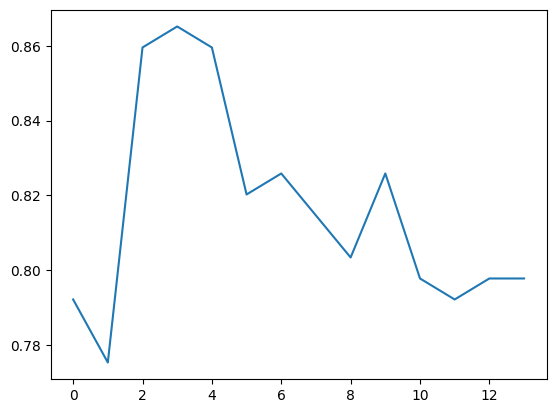

In [35]:
#4.3 Graficamos los moelode para saber cual es el que mejor dio 
# de score.
sb.lineplot(data=resultados)

In [36]:
# 4.4 Ya seleccionado el numero de profundidad del arbol lo usamos para predecir.
modelo = DecisionTreeClassifier(max_depth=4)
modelo.fit(X_ent,Y_Ent)
predicciones = modelo.predict(X_pruebas)
exactitud = accuracy_score(Y_Pruebas, predicciones)


In [37]:
# 4.5 Generamos el reporte de Clasificacione
from sklearn.metrics import classification_report
print(classification_report(Y_Pruebas, predicciones))

              precision    recall  f1-score   support

           0       0.86      0.93      0.89       107
           1       0.87      0.77      0.82        71

    accuracy                           0.87       178
   macro avg       0.87      0.85      0.86       178
weighted avg       0.87      0.87      0.86       178



In [38]:
# 4.6 Creamos la matriz de confusion para saber los resultados obtenidos
# 5.3 Validamos la Matriz de Confusion
from sklearn.metrics import confusion_matrix
confusion_matrix(Y_Pruebas,predicciones)


array([[99,  8],
       [16, 55]])

In [39]:
# 5.3.1 Damos formato a la Matriz de Confusion para entenderla
pd.DataFrame(confusion_matrix(Y_Pruebas,predicciones), 
             columns=["Pred: No", "Pred: Si"], 
             index=["Real: No", "Real: Si"])

# NOTA: Esto nos dice lo que esta haciendo el modelo
# Cuando el Modelo predijo que NO (Columna Pred:No) 
#        el valor Real que NO Sobrevivieron fue de 96, pero
#        cuando el Modelo predijo que NO, el valor real de que SI sobrevivieron
#        fueron de 20 
# Y lo mismo para la prediccion de SI, de si sobrevivieron.


,Pred: No,Pred: Si
Real: No,99,8
Real: Si,16,55


In [40]:
# NOTA : Podemos compara la matriz de confucion obtenidas con los arboles de desicion 
# Comparado con la matriz de confusion obtenida abajo 


[Text(0.5, 0.9, 'male <= 0.5\n0.47\n711\n[442, 269]\nMurio'),
 Text(0.25, 0.7, 'Pclass <= 2.5\n0.397\n256\n[70, 186]\nVivio'),
 Text(0.125, 0.5, 'Age <= 2.5\n0.1\n133\n[7, 126]\nVivio'),
 Text(0.0625, 0.3, 'Parch <= 1.5\n0.5\n2\n[1, 1]\nMurio'),
 Text(0.03125, 0.1, '0.0\n1\n[0, 1]\nVivio'),
 Text(0.09375, 0.1, '0.0\n1\n[1, 0]\nMurio'),
 Text(0.1875, 0.3, 'Fare <= 29.356\n0.087\n131\n[6, 125]\nVivio'),
 Text(0.15625, 0.1, '0.201\n53\n[6, 47]\nVivio'),
 Text(0.21875, 0.1, '0.0\n78\n[0, 78]\nVivio'),
 Text(0.375, 0.5, 'Fare <= 23.35\n0.5\n123\n[63, 60]\nMurio'),
 Text(0.3125, 0.3, 'Age <= 36.5\n0.49\n100\n[43.0, 57.0]\nVivio'),
 Text(0.28125, 0.1, '0.479\n93\n[37, 56]\nVivio'),
 Text(0.34375, 0.1, '0.245\n7\n[6, 1]\nMurio'),
 Text(0.4375, 0.3, 'Parch <= 0.5\n0.227\n23\n[20, 3]\nMurio'),
 Text(0.40625, 0.1, '0.0\n1\n[0, 1]\nVivio'),
 Text(0.46875, 0.1, '0.165\n22\n[20, 2]\nMurio'),
 Text(0.75, 0.7, 'Fare <= 26.269\n0.298\n455\n[372, 83]\nMurio'),
 Text(0.625, 0.5, 'Age <= 13.5\n0.194\n322\

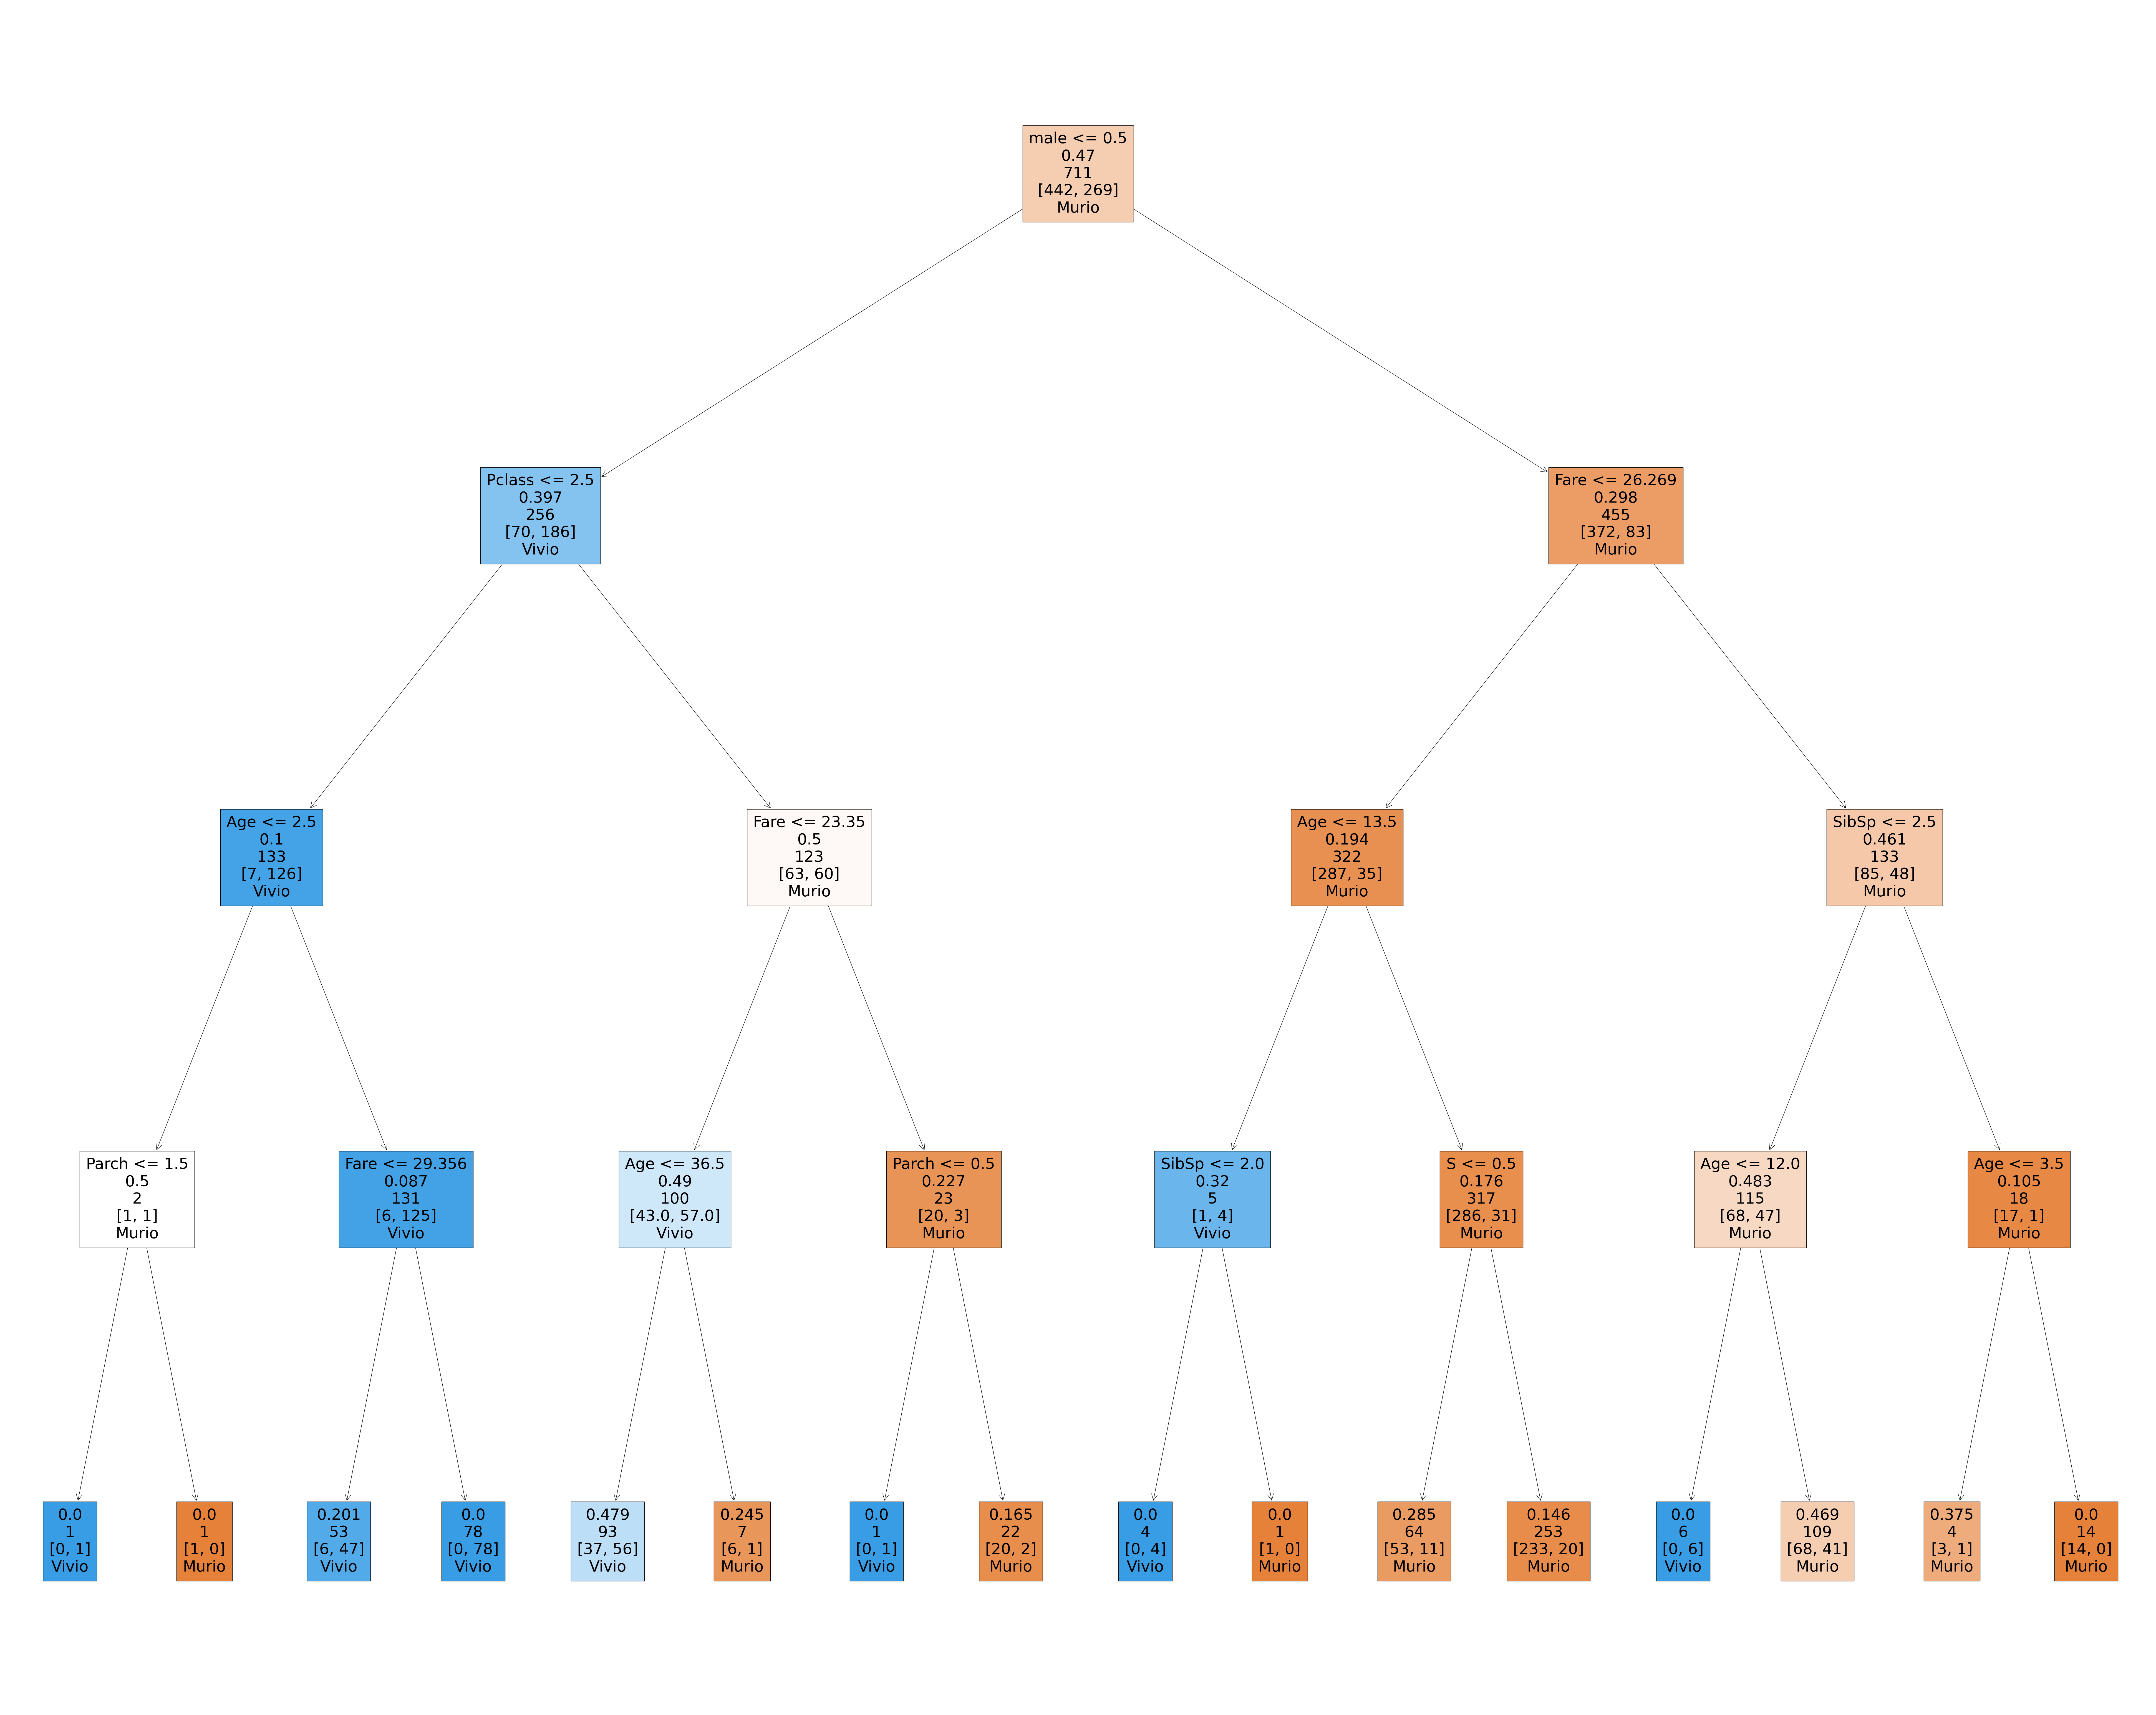

In [46]:
#5.4 Graficamos el arbol de desicion
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(100,80))
plot_tree(
    modelo,
    feature_names=X_ent.columns,
    class_names=["Murio","Vivio"],
    filled=True, label = "none"
)

# 4. HACEMOS PREDICCIONES CON NUESTRAS VARIABLES DE PRUEBA 

In [62]:
# 5.1 Validamos la exactitud del modelo
from sklearn.metrics import accuracy_score
accuracy_score(Y_Pruebas, predicciones)

0.8258426966292135

In [64]:
# 5.2 Validamos el Clasification Report
from sklearn.metrics import classification_report  
print(classification_report(Y_Pruebas, predicciones))

#El informe de clasificación tiene las siguientes secciones:

#Precisión (precision): La precisión es la proporción de instancias clasificadas como positivas que son realmente positivas. Se calcula como verdaderos positivos / (verdaderos positivos + falsos positivos).
#Recall (sensibilidad o tasa de verdaderos positivos): El recall es la proporción de instancias positivas que fueron correctamente clasificadas. Se calcula como verdaderos positivos / (verdaderos positivos + falsos negativos).
#F1-score: El F1-score es la media armónica de precisión y recall. Proporciona un equilibrio entre precisión y recall. Se calcula como 2 * (precisión * recall) / (precisión + recall).
#Soporte (support): El soporte es el número de ocurrencias de cada clase en el conjunto de datos.
#Macro avg: Promedio de las métricas (precisión, recall, F1-score) para todas las clases, sin tener en cuenta el desequilibrio de clases. Calculado como el promedio sin ponderar de las métricas.
#Weighted avg: Promedio de las métricas (precisión, recall, F1-score) para todas las clases, considerando el desequilibrio de clases. Calculado como el promedio ponderado de las métricas, donde cada métrica se pondera por el soporte de la clase correspondiente.

#El classification_report es útil para evaluar el rendimiento de un modelo de clasificación en cada clase y en general. Ayuda a identificar qué clases son bien clasificadas y cuáles pueden tener problemas de clasificación.

              precision    recall  f1-score   support

           0       0.83      0.90      0.86       107
           1       0.82      0.72      0.77        71

    accuracy                           0.83       178
   macro avg       0.83      0.81      0.81       178
weighted avg       0.83      0.83      0.82       178



In [66]:
# 5.3 Validamos la Matriz de Confusion
from sklearn.metrics import confusion_matrix
confusion_matrix(Y_Pruebas,predicciones)

array([[96, 11],
       [20, 51]])

In [68]:
# 5.3.1 Damos formato a la Matriz de Confusion para entenderla
pd.DataFrame(confusion_matrix(Y_Pruebas,predicciones), 
             columns=["Pred: No", "Pred: Si"], 
             index=["Real: No", "Real: Si"])

# NOTA: Esto nos dice lo que esta haciendo el modelo
# Cuando el Modelo predijo que NO (Columna Pred:No) 
#        el valor Real que NO Sobrevivieron fue de 96, pero
#        cuando el Modelo predijo que NO, el valor real de que SI sobrevivieron
#        fueron de 20 
# Y lo mismo para la prediccion de SI, de si sobrevivieron.

,Pred: No,Pred: Si
Real: No,96,11
Real: Si,20,51


# 5. HACEMOS UNA PREDICCION REAL


In [69]:
# 6. Vemos las columnas de los datos
datos.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,male,Q,S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


In [78]:
# 6. Difimos a una nueva persona
import numpy as np
nueva_persona = np.array([3,     # Definimois la Clase 3
                 35,    # Edad de 35 anios
                 0,     # Iba solo, no llevaba hermanos, esposa et.
                 0,
                 10,    # Pague $10 USD por se clase 3 
                 1,     # Soy Hombre "0"
                 0,     # NO sali del embarque Q
                 0      # No sali del embarque S
                ])

# Convertimos a nueva_persona en un arreglo bidimensional
nueva_persona = nueva_persona.reshape(1, -1)

prediccion_nuevaPersona = modelo.predict(nueva_persona)
#print(prediccion_nuevaPersona[0])
if prediccion_nuevaPersona[0] == 1:
    print(" Sobreviviste ")
else:
    print(" NO Sobreviviste")

 NO Sobreviviste


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
